# Fragrance Data Science Project: Exploratory Analysis and Recommendation Engine 

## Introduction

Fragrances contain hundreds of different combinations of notes, ingredients, and accords that influence how consumers perceive them. Using a dataset of over 24,000 fragrances, this project explores patterns in perfume composition, popularity, and consumer ratings.

In [1]:
import pandas as pd                  
import matplotlib.pyplot as plt        
import seaborn as sns; sns.set()
import numpy as np
import statsmodels.formula.api as smf
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("fra_cleaned.csv", sep=";", encoding="latin1")
df

,url,Perfume,Brand,Country,Gender,Rating Value,Rating Count,Year,Top,Middle,Base,Perfumer1,Perfumer2,mainaccord1,mainaccord2,mainaccord3,mainaccord4,mainaccord5
0,https://www.fragrantica.com/perfume/xerjoff/ac...,accento-overdose-pride-edition,xerjoff,Italy,unisex,"1,42",201,2022.0,"fruity notes, aldehydes, green notes","bulgarian rose, egyptian jasmine, lily-of-the-...","eucalyptus, pine",unknown,NaN,rose,woody,fruity,aromatic,floral
1,https://www.fragrantica.com/perfume/jean-paul-...,classique-pride-2024,jean-paul-gaultier,France,women,"1,86",70,2024.0,"yuzu, citruses","orange blossom, neroli","musk, blonde woods",unknown,NaN,citrus,white floral,sweet,fresh,musky
2,https://www.fragrantica.com/perfume/jean-paul-...,classique-pride-2023,jean-paul-gaultier,France,unisex,"1,91",285,2023.0,"blood orange, yuzu","neroli, orange blossom","musk, white woods",natalie gracia-cetto,quentin bisch,citrus,white floral,sweet,fresh spicy,musky
3,https://www.fragrantica.com/perfume/bruno-bana...,pride-edition-man,bruno-banani,Germany,men,"1,92",59,2019.0,"guarana, grapefruit, red apple","walnut, lavender, guava","vetiver, benzoin, amber",unknown,NaN,fruity,nutty,woody,tropical,NaN
4,https://www.fragrantica.com/perfume/jean-paul-...,le-male-pride-collector,jean-paul-gaultier,France,men,"1,93",632,2020.0,"mint, lavender, cardamom, artemisia, bergamot","caraway, cinnamon, orange blossom","vanilla, sandalwood, amber, cedar, tonka bean",francis kurkdjian,NaN,aromatic,warm spicy,fresh spicy,cinnamon,vanilla
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24058,https://www.fragrantica.com/perfume/o-boticari...,floratta,o-boticario,Brazil,women,"4,81",31,1992.0,"ozonic notes, peach","lily-of-the-valley, jasmine","musk, amber",thierry lecoule,NaN,white floral,ozonic,fresh,musky,powdery
24059,https://www.fragrantica.com/perfume/sultan-pas...,cheval-d-arabie,sultan-pasha-attars,UK,unisex,"4,81",26,2020.0,"taif rose, indian oud, white rose, olibanum, e...","bulgarian rose, indian oud, hay, leather, cive...","white amber, leather, hay, elemi resin, kyara ...",sultan pasha,NaN,rose,amber,fresh spicy,animalic,aromatic
24060,https://www.fragrantica.com/perfume/darkbeat-p...,khaox,darkbeat-parfums,Spain,unisex,"4,85",26,2020.0,"mint, lime, rum","lily-of-the-valley, fig leaf, cardamom","musk, oakmoss, amber, patchouli",josé m. giraldo,NaN,green,aromatic,citrus,fresh spicy,woody
24061,https://www.fragrantica.com/perfume/parfumerie...,aoud-no-1,parfumerie-bruckner,Germany,unisex,"4,86",28,2011.0,"apple, peach, saffron","plum, orange blossom, jasmine","agarwood (oud), sandalwood, vanilla",unknown,NaN,fruity,sweet,oud,woody,powdery


## Data Exploration

The analysis within this section seeks to answer several questions:

Which brands produce the largest fragrance collections?

Which countries dominate the fragrance industry?

Which fragrance notes appear most frequently?

Which notes are associated with higher user ratings?

### Initial Data Exploration and Cleaning

Before beginning the analysis, I explored the dataset to better understand its structure and identify any data quality issues that could affect the results. This included examining the dataset's dimensions, summary statistics, data types, missing values, and duplicate records. I also cleaned the data by converting the Rating Value column from a string to a numeric data type, ensuring it could be used for statistical calculations and visualizations.

In [3]:
df.shape

(24063, 18)

In [4]:
df.describe()

,Rating Count,Year
count,24063.000000,22026.000000
mean,501.396542,2012.455961
std,1429.484690,13.526737
min,26.000000,1781.000000
25%,56.000000,2010.000000
50%,127.000000,2015.000000
75%,360.000000,2019.000000
max,29858.000000,2024.000000


In [5]:
df.dtypes

url                 str
Perfume             str
Brand               str
Country             str
Gender              str
Rating Value        str
Rating Count      int64
Year            float64
Top                 str
Middle              str
Base                str
Perfumer1           str
Perfumer2           str
mainaccord1         str
mainaccord2         str
mainaccord3         str
mainaccord4         str
mainaccord5         str
dtype: object

In [6]:
duplicates = df.duplicated().sum()
print(f"Duplicate rows: {duplicates}")

Duplicate rows: 0


In [7]:
df.isna().sum()

url                 0
Perfume             0
Brand               0
Country             0
Gender              0
Rating Value        0
Rating Count        0
Year             2037
Top                 0
Middle              0
Base                0
Perfumer1           0
Perfumer2       22727
mainaccord1         0
mainaccord2        13
mainaccord3       114
mainaccord4       388
mainaccord5       981
dtype: int64

No duplicate rows were found in the dataset. Most variables also contained no missing values. However, the Year column had 2,037 missing values, and Perfumer2 was missing for most observations because many fragrances were created by a single perfumer. The mainaccord2 through mainaccord5 columns also contained some missing values, which is expected since not every fragrance has five listed accords. Because these missing values reflect the structure of the dataset rather than data quality issues, no rows or columns were removed.

In [8]:
df["Rating Value"] = (
    df["Rating Value"]
    .str.replace(",", ".", regex=False)
)

df["Rating Value"] = pd.to_numeric(df["Rating Value"], errors="coerce")


In [9]:
df["Rating Value"].dtype

dtype('float64')

Since Rating Value was originally stored as a stringdue to numbers being formatted with commas instead of periods (ex. 4,25 instead of 4.25), I replaced the commas with periods and converted the column to a numeric (float) data type. This allows me to perform calculations such as averages and other statistical analyses.

Which fragrance notes are most common?
Count the most frequent top, middle, or base notes.

Do men's, women's, and unisex fragrances receive different average ratings?
Which countries produce the highest-rated fragrances?

Similar to your brand analysis.
Does popularity (rating count) correlate with rating value?

Scatter plot of Rating Count vs Rating Value.
What are the most common fragrance accords?

Great visualization and easy to explain.

### Which countries produce the most fragrances, and which produce the highest-rated fragrances?

After cleaning and validating the dataset, I analyzed which countries produce the largest number of fragrances and whether those countries also receive the highest customer ratings.

I identified the top 10 countries by fragrance count and visualized the results using a horizontal bar chart. France accounts for the largest number of fragrances in the dataset, followed by the United States, which contributes roughly 60% as many fragrances. This highlights France's dominant presence within the fragrance industry.

To compare production volume with customer perception, I calculated the average fragrance rating for each country. Only countries with at least 20 fragrances were included to ensure the rankings were based on a representative sample.

Although France produces the largest number of fragrances in the dataset, it ranks ninth in average fragrance rating. Instead, countries such as Thailand, Saudi Arabia, and Oman have the highest average ratings. However, the differences between countries are relatively small, with average ratings ranging from approximately 3.9 to 4.2. Four of the five highest-rated countries are located in Asia, while the countries producing the largest numbers of fragrances are primarily located in Europe and North America. These findings suggest that producing more fragrances does not necessarily correspond to higher customer ratings.

In [10]:
country= df["Country"].value_counts().head(10)
country

Country
France     7261
USA        4473
Italy      3310
UK         1724
Brazil     1338
Spain      1307
UAE        1228
Germany     579
Sweden      416
Russia      398
Name: count, dtype: int64

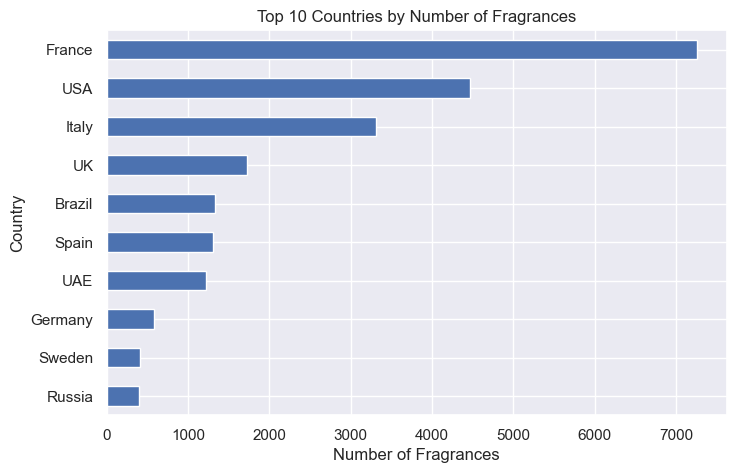

In [11]:
plt.figure(figsize=(8,5))
country.sort_values().plot(kind="barh")
plt.title("Top 10 Countries by Number of Fragrances")
plt.xlabel("Number of Fragrances")
plt.show()

In [12]:
country_rating = (df.groupby("Country").agg(Avg_Rating=("Rating Value", "mean"),Count=("Country", "count")))
country_rating = country_rating[country_rating["Count"] >= 30]
country_rating = country_rating.sort_values("Avg_Rating",ascending=False)
country_rating.head(10)

,Avg_Rating,Count
Country,,
Thailand,4.180702,57
Arabia saudi,4.161556,90
Oman,4.103136,118
UAE,4.058819,1228
Brazil,4.054462,1338
Greece,4.032101,119
UK,4.014977,1724
Latvia,3.982055,73
France,3.975465,7261


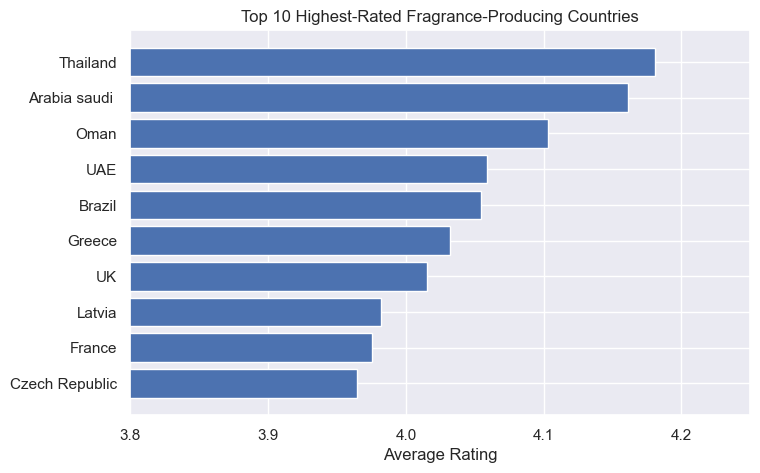

In [13]:
top10_countries = country_rating.head(10)

plt.figure(figsize=(8,5))
plt.barh(top10_countries.index, top10_countries["Avg_Rating"])
plt.xlabel("Average Rating")
plt.xlim(3.8, 4.25)
plt.title("Top 10 Highest-Rated Fragrance-Producing Countries")
plt.gca().invert_yaxis()
plt.show()

While France produces the largest number of fragrances in the dataset, quantity does not necessarily indicate quality. To investigate this relationship, I examined which countries produce the highest-rated fragrances based on average customer ratings. To determine which countries produce the highest-rated fragrances, I calculated the average fragrance rating for each country. I grouped the data by country and calculated each country's average fragrance rating. Because countries with only a few fragrances could appear artificially high due to a small sample size, I restricted the analysis to countries represented by at least 30 fragrances.

While France produces the largest number of fragrances in the dataset, it does not have the highest average rating. Instead, Thailand achieved the highest average fragrance rating (4.18), followed closely by Saudi Arabia (4.16) and Oman (4.10). Interestingly, several Middle Eastern and Asian countries appear near the top of the rankings, despite producing far fewer fragrances than France or the United States. Although these countries are ranked differently, the average ratings vary by only about 0.22 points, suggesting that overall fragrance quality is relatively consistent among the highest-rated countries.

Overall, the results suggest that countries producing the largest number of fragrances are not necessarily those producing the highest-rated fragrances. High customer ratings appear across both large and relatively small fragrance-producing countries, indicating that production volume alone is not a reliable indicator of fragrance quality.

### Which brands produce the most fragrances, and which produce the highest-rated fragrances?

I next examined which fragrance brands produce the largest product catalogs and whether those brands also receive the highest customer ratings.

The brand count analysis shows that Avon and Zara have the largest fragrance catalogs in the dataset, each with more than 500 fragrances. Avon and Zara have the largest fragrance catalogs in the dataset, each offering more than 500 fragrances. The remaining brands in the top ten have substantially smaller catalogs, indicating that only a handful of companies maintain exceptionally large fragrance portfolios.

To compare brand quality rather than production volume, I calculated each brand's average fragrance rating. Brands with fewer than 20 fragrances were excluded to reduce the influence of very small sample sizes.

The results show that brands with the largest fragrance catalogs are not necessarily the highest rated. While Avon and Zara produce the greatest number of fragrances, neither appears among the top-rated brands. Instead, several brands with more modest product catalogs achieve higher average ratings. The results indicate that larger fragrance catalogs do not necessarily translate into higher customer ratings. Several brands with relatively modest product portfolios outperform much larger brands, suggesting that maintaining a smaller catalog may allow companies to deliver more consistently well-rated fragrances.

In [14]:
brand= df["Brand"].value_counts().head(10)
brand

Brand
avon                  578
zara                  524
o-boticario           381
guerlain              347
natura                300
oriflame              290
yves-saint-laurent    197
dior                  196
givenchy              196
giorgio-armani        185
Name: count, dtype: int64

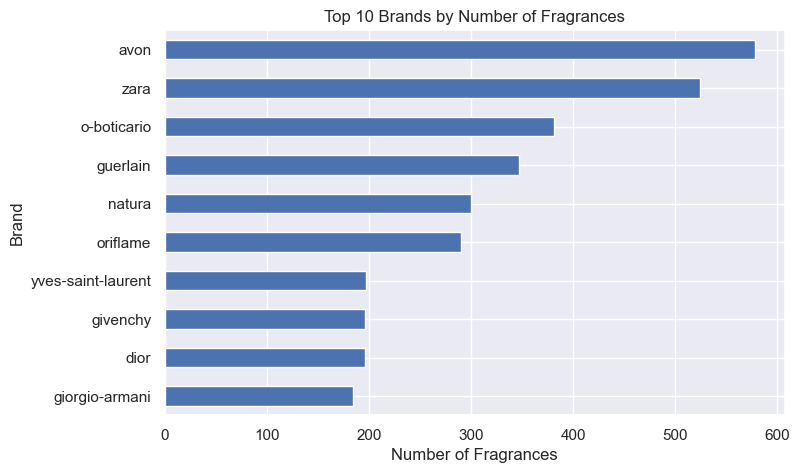

In [15]:
plt.figure(figsize=(8,5))
brand.sort_values().plot(kind="barh")
plt.title("Top 10 Brands by Number of Fragrances")
plt.xlabel("Number of Fragrances")
plt.show()

In [16]:
brand_rating = (df.groupby("Brand").agg(Avg_Rating=("Rating Value", "mean"),Count=("Brand", "count")))
brand_rating = brand_rating[brand_rating["Count"] >= 20]
brand_rating = brand_rating.sort_values("Avg_Rating", ascending=False)
top10_brands = brand_rating.head(10)
top10_brands

,Avg_Rating,Count
Brand,,
sultan-pasha-attars,4.436250,24
arabian-oud,4.308846,52
areej-le-dore,4.278824,51
ermenegildo-zegna,4.271852,27
maison-alhambra,4.255455,55
al-wataniah,4.247000,20
jean-patou,4.234103,39
roja-dove,4.213468,124
lorenzo-pazzaglia,4.204231,26


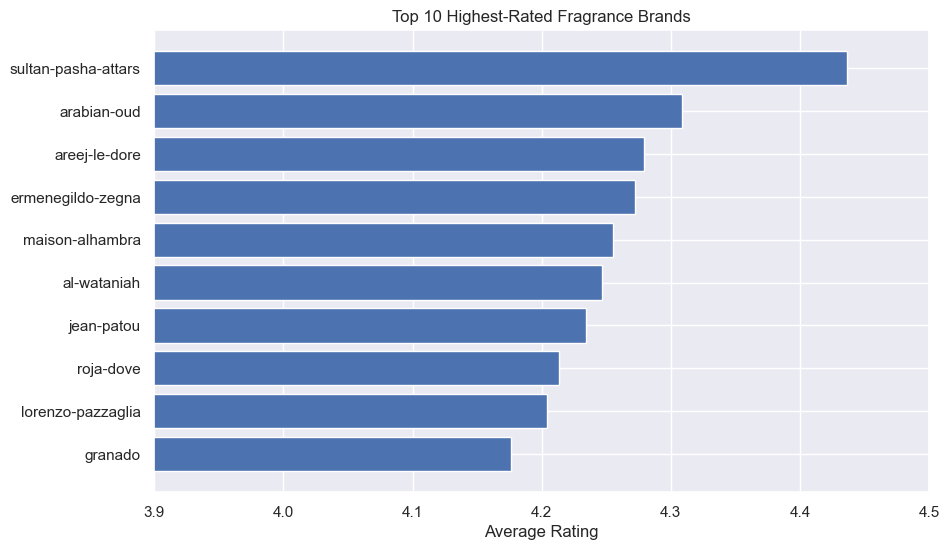

In [17]:
plt.figure(figsize=(10,6))
plt.barh(top10_brands.index[::-1], top10_brands["Avg_Rating"][::-1])
plt.title("Top 10 Highest-Rated Fragrance Brands")
plt.xlabel("Average Rating")
plt.xlim(3.9, 4.5)
plt.show()

The brand distribution shows that Avon and Zara have the largest fragrance catalogs in the dataset, with 578 and 524 fragrances, respectively. They are followed by O Boticário (381 fragrances) and Guerlain (347 fragrances), while the remaining brands in the top 10 each contribute fewer than 300 fragrances. This indicates that only a small number of brands maintain exceptionally large fragrance portfolios.

To investigate whether producing more fragrances is associated with higher customer satisfaction, I calculated the average rating for each brand. To ensure the results were representative, I limited the analysis to brands with at least 20 fragrances, preventing brands with only a few highly rated fragrances from disproportionately influencing the rankings.

The highest-rated brands received average ratings ranging from 4.18 to 4.44, indicating relatively consistent customer satisfaction among the top performers. Interestingly, none of the brands with the largest fragrance catalogs—such as Avon and Zara—appear among the highest-rated brands. This suggests that producing a larger number of fragrances does not necessarily result in higher customer ratings. One notable exception is Roja Dove, which ranks among the highest-rated brands while also offering a relatively large catalog of 124 fragrances, demonstrating that some brands can successfully balance both a broad product lineup and strong customer satisfaction.

### What are the most popular notes, and which notes are in the highest rated fragrances?

To better understand the composition of fragrances, I analyzed the frequency of fragrance notes across the top, middle, and base layers. Because each fragrance contains multiple notes stored as comma-separated strings, I first separated each note into an individual observation before counting its occurrence. This analysis identifies the ingredients most commonly used in fragrance compositions and investigates whether the notes associated with the highest-rated fragrances differ from those that are simply the most common.

In [18]:
top_notes = df["Top"].str.split(",")
middle_notes = df["Middle"].str.split(",")
base_notes = df["Base"].str.split(",")

In [19]:
top_all = top_notes.explode()
middle_all = middle_notes.explode()
base_all = base_notes.explode()

In [20]:
top_all = top_all.str.strip().str.lower()
middle_all = middle_all.str.strip().str.lower()
base_all = base_all.str.strip().str.lower()

In [21]:
top_counts = top_all.value_counts()
middle_counts = middle_all.value_counts()
base_counts = base_all.value_counts()

#### What are the top 10 most common top notes?

Top notes are the first scents perceived after a fragrance is applied and therefore play an important role in forming the initial impression. The results show that citrus ingredients overwhelmingly dominate this category, with bergamot appearing in over 8,500 fragrances—more than twice as often as the second most common top note, mandarin orange. Lemon, grapefruit, and orange also rank among the top ingredients, indicating that fragrance designers frequently rely on fresh, bright citrus openings. The inclusion of pink pepper and cardamom suggests that spicy accords are commonly used to add complexity, while lavender provides a fresh aromatic element.

In [22]:
top_counts.head(10)

Top
bergamot           8535
mandarin orange    3933
lemon              2966
grapefruit         2185
pink pepper        2016
cardamom           1527
orange             1502
pear               1317
black currant      1303
lavender           1182
Name: count, dtype: int64

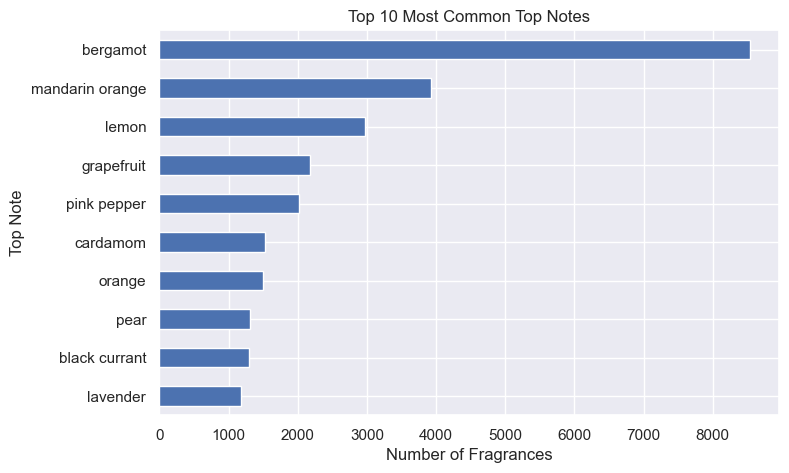

In [23]:
plt.figure(figsize=(8,5))
top_counts.head(10).sort_values().plot(kind="barh")
plt.title("Top 10 Most Common Top Notes")
plt.xlabel("Number of Fragrances")
plt.ylabel("Top Note")
plt.show()

#### What are the top 10 most common middle notes?

Middle notes form the heart of a fragrance and define much of its overall character. Unlike the citrus-heavy top notes, the most common middle notes are overwhelmingly floral. Jasmine and rose appear far more frequently than any other ingredients, followed by lily-of-the-valley, orange blossom, violet, iris, ylang-ylang, and peony. This suggests that floral accords serve as the foundation of many fragrance compositions across different brands and fragrance styles. Lavender and geranium provide fresh herbal accents, but floral ingredients clearly dominate this stage.

In [24]:
middle_counts.head(10)

Middle
jasmine               7110
rose                  5376
lily-of-the-valley    2319
orange blossom        1972
violet                1785
iris                  1760
ylang-ylang           1737
geranium              1689
lavender              1516
peony                 1343
Name: count, dtype: int64

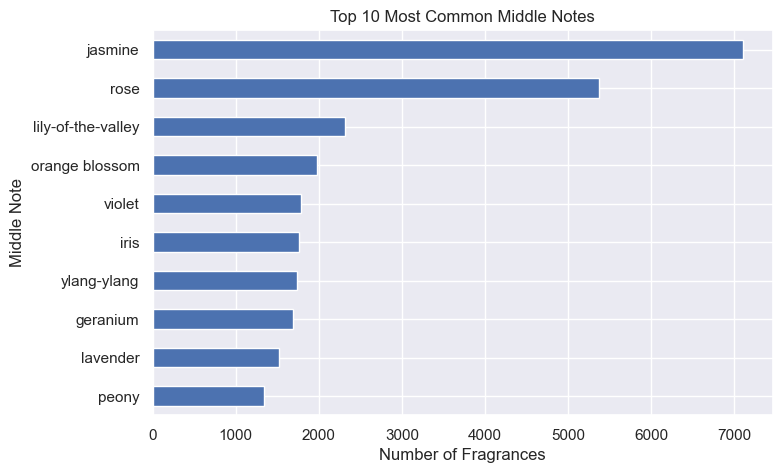

In [25]:
plt.figure(figsize=(8,5))
middle_counts.head(10).sort_values().plot(kind="barh")
plt.title("Top 10 Most Common Middle Notes")
plt.xlabel("Number of Fragrances")
plt.ylabel("Middle Note")
plt.show()

#### What are the top 10 most common base notes?

Base notes provide the lasting impression of a fragrance and contribute significantly to its longevity. Musk is by far the most common base note, appearing in over 10,000 fragrances, highlighting its importance in creating depth and lasting performance. Sandalwood, amber, patchouli, cedar, and vetiver demonstrate the widespread use of woody accords, while vanilla and tonka bean introduce warm gourmand characteristics. Overall, fragrance bases tend to emphasize rich, warm, and long-lasting ingredients that complement the lighter notes that evaporate earlier.

In [26]:
base_counts.head(10)

Base
musk          10655
sandalwood     7335
amber          7171
vanilla        6173
patchouli      5957
cedar          4461
vetiver        3343
tonka bean     2990
oakmoss        1826
white musk     1689
Name: count, dtype: int64

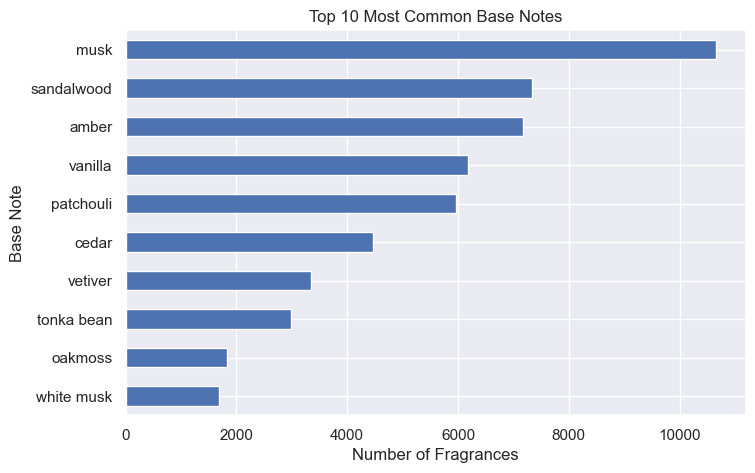

In [27]:
plt.figure(figsize=(8,5))
base_counts.head(10).sort_values().plot(kind="barh")
plt.title("Top 10 Most Common Base Notes")
plt.xlabel("Number of Fragrances")
plt.ylabel("Base Note")
plt.show()

#### What are the most common notes overall?

When all fragrance layers are combined, musk emerges as the most common ingredient across the entire dataset, followed by bergamot, sandalwood, jasmine, amber, patchouli, vanilla, and rose. This demonstrates that although fragrances begin with bright citrus openings, they typically rely on woody, musky, floral, and warm gourmand ingredients throughout the remainder of their composition. The results suggest that successful fragrance formulations balance freshness at the opening with richer, longer-lasting base materials.

In [28]:
all_notes = pd.concat([top_all, middle_all, base_all])
all_counts = all_notes.value_counts()
all_counts.head(15)

musk               11022
bergamot            8617
sandalwood          8059
jasmine             7745
amber               7730
patchouli           7254
vanilla             6742
rose                6251
cedar               5628
mandarin orange     4007
vetiver             3911
tonka bean          3347
lemon               3036
lavender            2732
orange blossom      2679
Name: count, dtype: int64

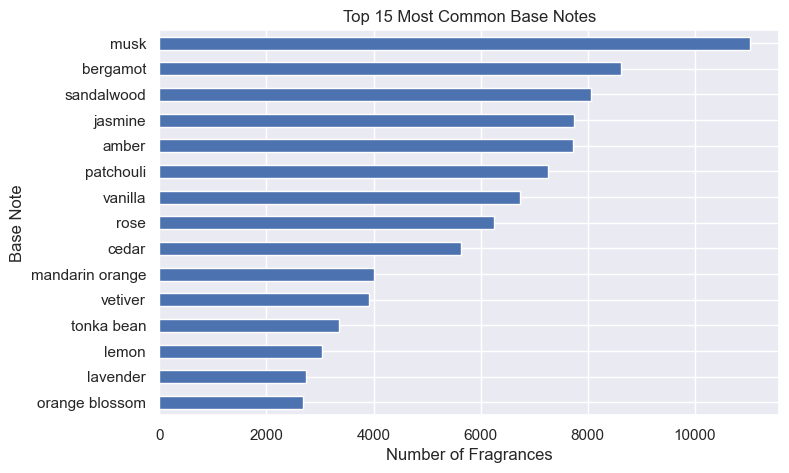

In [29]:
plt.figure(figsize=(8,5))
all_counts.head(15).sort_values().plot(kind="barh")
plt.title("Top 15 Most Common Base Notes")
plt.xlabel("Number of Fragrances")
plt.ylabel("Base Note")
plt.show()

#### Which notes are associated with the highest-rated fragrances?

The notes associated with the highest-rated fragrances differ substantially from the most commonly used ingredients. Rather than common citrus fruits or traditional florals, the highest-rated fragrances frequently contain premium materials such as Indian oud, Cambodian oud, agarwood, Taif rose, Rose de Mai, and opoponax. Many of these ingredients are characteristic of niche and luxury perfumery, where complex natural materials are emphasized. While these notes appear less frequently across the overall dataset, their higher average ratings suggest that consumers may associate richer, more distinctive ingredients with higher-quality fragrances.

In [30]:
notes = df[["Top", "Middle", "Base", "Rating Value"]].copy()
notes["All_Notes"] = (notes["Top"].fillna("") + "," + notes["Middle"].fillna("") + "," + notes["Base"].fillna(""))

In [31]:
notes["All_Notes"] = notes["All_Notes"].str.split(",")

In [32]:
notes = notes.explode("All_Notes")

In [33]:
notes["All_Notes"] = (notes["All_Notes"].str.strip().str.lower())
notes = notes[notes["All_Notes"] != ""]

In [34]:
note_stats = (notes.groupby("All_Notes").agg(Avg_Rating=("Rating Value", "mean"),Count=("All_Notes", "count")))
note_stats = note_stats[note_stats["Count"] >= 30]

In [35]:
top10_notes = (note_stats.sort_values("Avg_Rating", ascending=False).head(10))
top10_notes

,Avg_Rating,Count
All_Notes,,
indian oud,4.247164,67
cambodian oud,4.143559,59
marjoram,4.142703,37
natural musk,4.132093,43
civet,4.131852,270
rose de mai,4.125714,91
agarwood,4.115938,32
opoponax,4.109194,248
taif rose,4.102857,84


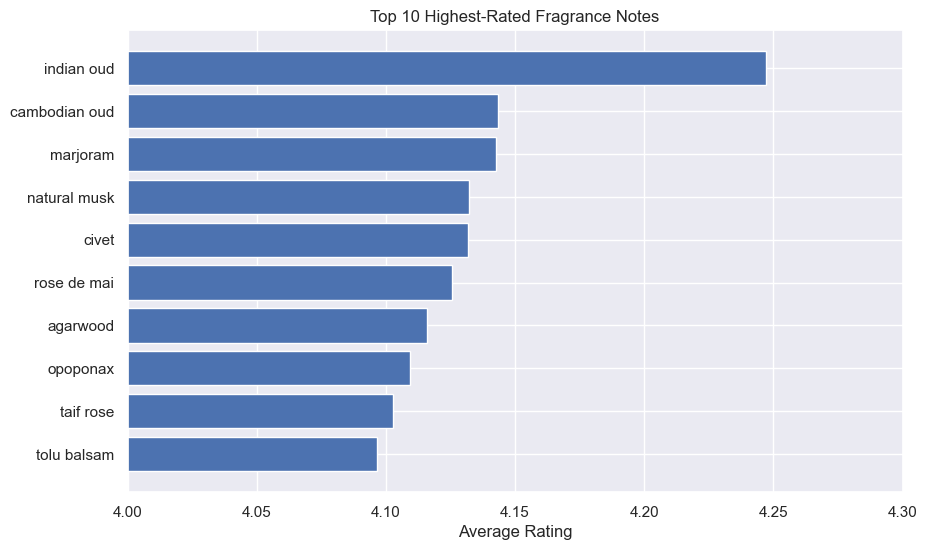

In [36]:
plt.figure(figsize=(10,6))
plt.barh(top10_notes.index[::-1],top10_notes["Avg_Rating"][::-1])
plt.title("Top 10 Highest-Rated Fragrance Notes")
plt.xlabel("Average Rating")
plt.xlim(4.0, 4.3)
plt.show()

#### How do the most common notes compare with the highest rated notes?

Comparing the two analyses reveals that the most frequently used ingredients are not necessarily those associated with the highest customer ratings. Common notes such as bergamot, musk, jasmine, vanilla, and sandalwood dominate the overall fragrance market because they provide versatile building blocks for many fragrance styles. However, the highest-rated fragrances more frequently feature niche ingredients such as oud, agarwood, opoponax, civet, and specialty rose varieties. This suggests that while common ingredients create mass-market appeal, more distinctive and luxurious note combinations may contribute to stronger customer satisfaction.

## Fragrance Predictor Using Perfumes

To extend the analysis beyond descriptive statistics and data exploration, I built a content-based fragrance recommendation system. Rather than relying on customer reviews or popularity, the model recommends fragrances based on the similarity of their note compositions. This demonstrates how machine learning techniques can be applied to product recommendation problems using only product attributes.

In [37]:
df["All_Notes"] = (df["Top"].fillna("") + "," +df["Middle"].fillna("") + "," +df["Base"].fillna(""))

In [38]:
df["All_Notes"] = df["All_Notes"].str.lower()

df["All_Notes"] = df["All_Notes"].apply(
    lambda x: [note.strip() for note in x.split(",")])

Each fragrance contains three separate note pyramids (top, middle, and base). To compare fragrances based on their complete scent profile, I combined these into a single list of notes for every fragrance. I also standardized the note names by converting them to lowercase and removing extra whitespace so that notes such as "Vanilla" and "vanilla" would be treated as the same feature.

In [39]:
from sklearn.preprocessing import MultiLabelBinarizer
mlb = MultiLabelBinarizer()
note_matrix = pd.DataFrame(
    mlb.fit_transform(df["All_Notes"]),
    columns=mlb.classes_,
    index=df.index)

Machine learning models cannot directly compare lists of text. Therefore, I used MultiLabelBinarizer to transform each fragrance into a binary feature vector, where each column represents a fragrance note and a value of 1 indicates that the note is present. This produces a numerical representation that allows fragrances with similar note compositions to be compared mathematically.

In [40]:
from sklearn.metrics.pairwise import cosine_similarity
similarity = cosine_similarity(note_matrix) 

Once every fragrance was represented as a binary vector, I calculated the cosine similarity between every pair of fragrances. Cosine similarity measures how similar two fragrances are based on the notes they share, regardless of the total number of notes contained in each fragrance. Fragrances with more overlapping notes receive higher similarity scores.

In [41]:
def recommend_by_perfume(fragrance_name, n=10):
    idx = df[df["Perfume"] == fragrance_name].index[0]
    sims = list(enumerate(similarity[idx]))
    sims = sorted(sims, key=lambda x: x[1], reverse=True)[1:n+1]
    recommendations = df.iloc[[i[0] for i in sims]][["Perfume", "Brand", "Rating Value"]].copy()
    recommendations["Similarity Score"] = [round(i[1], 2) for i in sims]
    return recommendations

Finally, I created a recommendation function that accepts the name of a fragrance and returns the five most similar fragrances in the dataset. The function locates the selected fragrance, retrieves its cosine similarity scores, ranks all other fragrances from most to least similar, and returns the top recommendations along with their brands and average ratings.

In [42]:
recommend_by_perfume("champagne-toast")

,Perfume,Brand,Rating Value,Similarity Score
4274,black-amber-parfum-intense,zara,3.72,0.55
17707,la-cautiva,fueguia-1833,4.13,0.55
9641,rose-bourbon,princesse-marina-de-bourbon,3.90,0.52
21721,the-wedding-silk-santal-36,kayali-fragrances,4.31,0.51
14051,tommy-bahama-very-cool,tommy-bahama,4.03,0.45
3034,wildberry-chamomile,bath-body-works,3.66,0.44
2624,black-amber,zara,3.63,0.42
6189,let-s-travel-to-miami-for-women,mandarina-duck,3.79,0.42
6238,azzaro-club-women,azzaro,3.80,0.42
8651,quartz-je-t-aime,molyneux,3.87,0.42


In [64]:
recommend_by_perfume("eclaire")

,Perfume,Brand,Rating Value,Similarity Score
2971,vanilla-ice-cream,jeanne-arthes,3.65,0.63
19104,golden-musk,orientica,4.18,0.58
23772,carashmellow,essnce,4.54,0.58
23867,i-matti-milk-s-note,eminence-parfums,4.57,0.58
13691,coco-cabana,sol-de-janeiro,4.02,0.53
17613,caramel-sunset,comptoir-sud-pacifique,4.13,0.53
21009,tutti-dolci-golden-honey-praline,bath-body-works,4.27,0.53
5600,marvelous,sapientiae-niche,3.77,0.53
6946,zara-woman-gold-2021,zara,3.82,0.53
12691,lamsa,arabian-oud,3.99,0.53


In [44]:
recommend_by_perfume("yara")

,Perfume,Brand,Rating Value,Similarity Score
20851,vanille-orient,m-micallef,4.26,0.63
24038,zukhruf-pink,zimaya,4.72,0.62
4027,cozy-serenade,zara,3.71,0.61
7555,give-me-a-sign-into-the-joyful,zara,3.84,0.61
5561,boum-do-brazil,jeanne-arthes,3.77,0.59
6805,forever,ciclo-cosmeticos,3.81,0.59
14881,wild-glow,jennifer-lopez,4.05,0.59
565,orangerie-lei,faberlic,3.38,0.58
3144,montana-mood-sensual,montana,3.66,0.58
7614,orchidee-gourmande,adopt-parfums,3.84,0.58


I evaluated the recommendation engine by testing it with several fragrances that I personally own and love. The recommended perfumes consistently received high cosine similarity scores, indicating that they share similar note compositions with the original fragrance. Because the model relies solely on fragrance notes, it recommends perfumes based on scent profile rather than brand, making it an effective content-based recommendation system.

One limitation of this approach is that every note is weighted equally. In reality, some notes are much more prominent than others, and concentration or note intensity is not captured in the dataset. Future work could assign different weights to top, middle, and base notes or incorporate user ratings to create a hybrid recommendation system.

## Fragrance Predictor Using Notes

While the previous recommendation engine identifies perfumes similar to an existing fragrance, this model allows users to discover new perfumes based on the fragrance notes they enjoy. Instead of requiring a perfume name, users simply provide a list of preferred notes, and the model recommends fragrances with the most similar note compositions.

In [45]:
def recommend_by_notes(notes, n=10):

    notes = [note.lower().strip() for note in notes]

    user_vector = pd.DataFrame(
        [[0]*len(note_matrix.columns)],
        columns=note_matrix.columns)
    
    for note in notes:
        if note in user_vector.columns:
            user_vector.loc[0, note] = 1

    sims = cosine_similarity(user_vector, note_matrix)[0]

    df_results = df.copy()
    df_results["Similarity Score"] = sims
    return (df_results.sort_values("Similarity Score", ascending=False)
        [["Perfume","Brand","Rating Value","Similarity Score"]]
        .head(n))

Each fragrance was represented as a binary vector indicating the presence or absence of every fragrance note in the dataset. When a user enters a list of preferred notes, those notes are converted into the same binary representation. Cosine similarity is then calculated between the user's note profile and every fragrance in the dataset. The fragrances with the highest similarity scores are returned as recommendations.

I tested the model using two different note combinations representing distinct fragrance profiles. In both cases, the recommendation engine returned fragrances that shared many of the requested notes while also introducing perfumes from a variety of brands. Higher similarity scores indicate that a fragrance contains a larger proportion of the selected notes.

In [54]:
recommend_by_notes(["vanilla", "oud", "citrus"])

,Perfume,Brand,Rating Value,Similarity Score
7819,awraq-al-oud,lattafa-perfumes,3.85,0.436436
20687,elevated-oud,zara,4.25,0.436436
13109,oud-oak,just-jack,4.00,0.408248
14193,vanille,molinard,4.03,0.408248
3207,oudgasm-rose-oud-16-eau-de-parfum-intense,kayali-fragrances,3.67,0.408248
2897,bayaan,lattafa-perfumes,3.65,0.384900
936,oudgasm-cafe-oud-19-eau-de-parfum-intense,kayali-fragrances,3.46,0.384900
7471,mango-aoud,gritti,3.84,0.384900
23612,shaghaf-oud-elixir,swiss-arabian,4.50,0.384900
11502,midnight-whisper,day-three,3.95,0.384900


In [53]:
recommend_by_notes(["rose", "oud", "amber", "musk"])

,Perfume,Brand,Rating Value,Similarity Score
22370,red-evening,massimo-dutti,4.35,0.866025
12917,essence-eau-de-musc,narciso-rodriguez,4.00,0.750000
5347,rose-sensuelle,lpdo,3.76,0.750000
8955,elle,verset-parfums,3.88,0.750000
15510,amber-oudh,rasasi,4.07,0.750000
10360,wild-roses,the-woods-collection,3.92,0.750000
9473,velvet-rose,lattafa-perfumes,3.90,0.670820
5174,make-b-barbie-edition,o-boticario,3.76,0.670820
11024,essence-d-or,elode,3.94,0.670820
19824,woody,arabian-oud,4.21,0.670820


To evaluate the recommendation engine, I tested it using two different sets of fragrance notes representing distinct scent profiles. The first reccomendation contained sweet and fruity notes (vanilla, pear, jasmine), while the second focused on warm oriental notes (rose, oud, amber, musk).

For the sweet fragrance profile, the model recommended perfumes such as La Belle Le Parfum, Sultry Pear Eau de Parfum, and When in Rio, all of which contain gourmand, fruity, or floral accords. The highest-ranked recommendation achieved a match score of 1.00, indicating an exact match to the requested note combination.

The second query produced recommendations including Amber Oudh, Rose Sensuelle, Velvet Rose, and Woody, which all feature rich amber, rose, oud, or woody compositions. These fragrances received high similarity scores ranging from approximately 0.67 to 0.87, showing that the model successfully identified perfumes with similar note structures.

Overall, the recommendation engine consistently returned fragrances with comparable scent compositions despite originating from different brands. This suggests that the model is learning relationships between fragrance notes rather than relying on brand names or popularity, making it useful for discovering perfumes based on preferred scent profiles.

## Conclusion

### Summary

This project explored a dataset of fragrances to better understand trends in the perfume industry and demonstrate how data science techniques can be applied to recommendation systems. After cleaning and preprocessing the data, I analyzed fragrance production by country and brand, identified the most common and highest-rated fragrance notes, explored note co-occurrence patterns, and examined how fragrance preferences vary across countries.

Beyond exploratory data analysis, I developed two content-based recommendation systems using fragrance note compositions. The first recommends perfumes that are similar to an existing fragrance, while the second allows users to receive personalized recommendations by providing a list of fragrance notes they enjoy. Both models represent fragrances as binary note vectors and use cosine similarity to identify perfumes with the most similar scent profiles.

Overall, this project demonstrates the complete data science workflow, including data cleaning, feature engineering, exploratory data analysis, visualization, and machine learning. It also highlights how structured product attributes can be transformed into meaningful recommendations without relying on user ratings or purchase history.

Future improvements could include weighting top, middle, and base notes differently, incorporating additional fragrance attributes such as release year or fragrance concentration, and developing an interactive web application that allows users to explore recommendations in real time.

### Key Takeaways

-Cleaned and prepared a real-world fragrance dataset for analysis.

-Identified trends in fragrance production across countries and brands.

-Analyzed the popularity and ratings of individual fragrance notes.

-Explored relationships between fragrance notes through co-occurrence analysis.

-Built two content-based recommendation systems using cosine similarity.

-Applied feature engineering and machine learning techniques to solve a practical recommendation problem.